# Contoh dashboard harga Mangga Manalagi

Prototipe (matplotlib + seaborn + ipywidgets) sebelum dibuat di `/admin/pasar`.
Aturan lengkap: `docs/superpowers/specs/2026-11-13-dashboard-manalagi-design.md`.
Nomor grafik sama dengan dokumen desain.

| # | Grafik | Jenis |
|---|---|---|
| 1 | Angka utama: median, rata-rata, tertimbang terjual | potret (hari terakhir rentang) |
| 2 | Histogram harga per kg + median + harga Ibuk | potret (hari terakhir rentang) |
| 3 | Perubahan harga (%) sejak titik pertama: produk yang sama vs semua produk | tren |
| 6 | Peringatan lonjakan: pasar + toko | tren |

**Cara pakai:** *Run All*, lalu pakai tombol filter di bagian paling bawah.
Bagian **Langkah 1** menghitung semua angka (tabel `baris` dan `harian`): itulah yang nanti
dikirim ke Supabase. **Langkah 2** hanya menyaring dan menggambar.

In [1]:
from datetime import date

import duckdb
import ipywidgets as w
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Parameter detektor lonjakan dan SQL hitungan ada di dashboard_manalagi.py (satu salinan,
# dipakai juga oleh kirim_supabase.py). Ubah parameternya di sana, bukan di sini.
from dashboard_manalagi import AMBANG_PASAR, AMBANG_TOKO, JENDELA_HARI, MIN_DATA, hitung

HARGA_IBUK = 30_000      # CONTOH: ganti dengan harga jual Ibuk per kg

NAMA_PASAR = {"semua": "Semua marketplace", "tokopedia": "Tokopedia", "blibli": "Blibli"}

# Palet dataviz (mode terang). Teks memakai tinta, bukan warna seri.
BIRU, ORANYE, MERAH, BIRU_PUDAR = "#2a78d6", "#eb6834", "#e34948", "#86b6ef"
TINTA, TINTA_2, REDUP = "#0b0b0b", "#52514e", "#898781"
GRID, SUMBU, PERMUKAAN = "#e1e0d9", "#c3c2b7", "#fcfcfb"

sns.set_theme(style="whitegrid", font="Segoe UI", rc={
    "figure.facecolor": PERMUKAAN, "axes.facecolor": PERMUKAAN,
    "axes.edgecolor": SUMBU, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.labelcolor": TINTA_2, "xtick.color": REDUP, "ytick.color": REDUP,
    "text.color": TINTA, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "lines.linewidth": 2,
})

def rupiah(x, _=None):
    return "Rp" + f"{x:,.0f}".replace(",", ".")

RUPIAH = mtick.FuncFormatter(rupiah)

## Langkah 1: hitung dalam SQL (ini yang dikirim ke Supabase)

SQL-nya ada di `dashboard_manalagi.py`; `kirim_supabase.py` memakai fungsi yang sama.

**Tabel `baris`: satu baris per produk per hari.** Kolom hitungan:
- `faktor` = harga hari ini / harga pengamatan sebelumnya produk itu (kosong kalau jedanya
  lebih dari `MAKS_JEDA_HARI`). Bahan indeks berantai.
- `rasio_jendela` = harga hari ini / median harga produk itu selama `JENDELA_HARI` hari
  sebelumnya (kosong kalau datanya kurang dari `MIN_DATA` hari).
- `lonjak_toko` = rasio menyimpang ≥ `AMBANG_TOKO` **dan** harganya berubah hari itu, jadi satu
  perubahan ditandai sekali.

Semua dihitung pada **seluruh data** sebelum disaring (aturan D di dokumen desain).

In [ ]:
# Langkah 1: tabel `baris` (satu baris per produk per hari) dan `harian` (satu baris per tanggal
# per pasar). SQL-nya di dashboard_manalagi.py, sama persis dengan yang dikirim ke Supabase.
# read_only + langsung ditutup: muat terjadwal 06:00/12:00 butuh gudang tidak sedang dibuka.
with duckdb.connect("warehouse/harga_buah.duckdb", read_only=True) as con:
    baris, harian = (d.to_pandas() for d in hitung(con))
# Notebook ini belum mengenal wilayah: hanya deret `semua` (filter wilayah ada di web).
harian = harian[harian["wilayah"] == "semua"].drop(columns="wilayah")
baris["tanggal"] = pd.to_datetime(baris["tanggal"])
harian["tanggal"] = pd.to_datetime(harian["tanggal"])

print(f"baris: {len(baris)} baris × {baris.shape[1]} kolom, {baris['produk_key'].nunique()} produk, "
      f"{baris['tanggal'].nunique()} hari ({baris['tanggal'].min():%d %b %Y} – {baris['tanggal'].max():%d %b %Y}), "
      f"{int(baris['lonjak_toko'].sum())} lonjakan toko")
print(f"harian: {len(harian)} baris × {harian.shape[1]} kolom")
harian[harian["pasar"] == "semua"].drop(columns="pasar").set_index("tanggal").round(3)

**Tabel `harian`: satu baris per tanggal per pasar** (`semua`, `blibli`, `tokopedia`).

- `median`, `rata_rata`, `tertimbang` (bobot `terjual_min`, perkiraan kasar karena itu jumlah
  terjual seumur toko): grafik 1.
- `indeks_berantai`: grafik 3. Mulai dari 1 × median hari pertama, lalu dikali median `faktor`
  setiap hari. Produk yang absen tidak menggeser garis, dan "normal"-nya tidak basi walau
  datanya 10 tahun.
- `median_rasio`, `lonjak_pasar`, `naik`, `turun`: grafik 6.

## Langkah 2: saring dan gambar

Aturan dari dokumen desain:
- **Kunci rentang**: preset terkunci kalau data marketplace terpilih lebih pendek dari preset
  (tahun kalender sebenarnya). *Semua* dan *Kustom* tidak pernah terkunci.
- **Kerapatan otomatis**: ≤ 90 hari → per hari; lebih → per bulan (1 tahun = 12 titik).
  Harga dan rasio digabung dengan **median**, jumlah lonjakan toko **dijumlah**, periode
  ditandai lonjakan pasar kalau **minimal satu hari** di dalamnya lonjakan.
- **Hari kosong** tetap kosong (garis putus); cakupan ditulis di atas grafik.
- **Grafik potret** (1, 2) memakai hari terakhir yang berdata di dalam rentang.

In [3]:
DURASI = {"30 hari": pd.DateOffset(days=30), "1 tahun": pd.DateOffset(years=1),
          "5 tahun": pd.DateOffset(years=5)}
ATURAN = {"jumlah_produk": "median", "median": "median", "rata_rata": "median",
          "tertimbang": "median", "indeks_berantai": "median", "median_rasio": "median",
          "naik": "sum", "turun": "sum", "lonjak_pasar": "max", "berdata": "sum"}
LEBAR_BATANG = {"hari": 0.6, "bulan": 20}


def batas_data(pasar):
    h = harian[harian["pasar"] == pasar]
    return h["tanggal"].min(), h["tanggal"].max()


def status_preset(pasar):
    # {preset: (terbuka, pesan)}
    awal, akhir = batas_data(pasar)
    ada = (akhir - awal).days + 1
    hasil = {}
    for nama, durasi in DURASI.items():
        perlu = ((awal + durasi) - awal).days          # 365/366 per tahun, bukan 360
        terbuka = ada >= perlu
        hasil[nama] = (terbuka, "" if terbuka else
                       f"{nama}: terbuka setelah {perlu} hari data (sekarang {ada}/{perlu})")
    return hasil


def rentang_preset(pasar, nama):
    awal, akhir = batas_data(pasar)
    if nama == "Semua":
        return awal, akhir
    return max(awal, akhir - DURASI[nama] + pd.Timedelta(days=1)), akhir


def kerapatan(mulai, akhir):
    if (akhir - mulai).days + 1 <= 90:
        return "D", "hari"
    return "MS", "bulan"   # lebih dari 90 hari: per bulan (14 Nov: per minggu dihapus)


def deret(pasar, mulai, akhir):
    h = harian[(harian["pasar"] == pasar) & harian["tanggal"].between(mulai, akhir)]
    h = h.drop(columns="pasar").set_index("tanggal").reindex(pd.date_range(mulai, akhir, freq="D"))
    h["berdata"] = h["jumlah_produk"].notna().astype(int)
    h["lonjak_pasar"] = h["lonjak_pasar"].astype(float)
    kode, satuan = kerapatan(mulai, akhir)
    if kode != "D":
        h = h.resample(kode).agg(ATURAN)
        kosong = h["berdata"] == 0
        h.loc[kosong, ["naik", "turun", "lonjak_pasar"]] = np.nan
    return h, satuan


def potret(pasar, mulai, akhir):
    b = baris if pasar == "semua" else baris[baris["sumber"] == pasar]
    b = b[b["tanggal"].between(mulai, akhir)]
    hari = b["tanggal"].max()
    return b[b["tanggal"] == hari], hari


def _sumbu_tanggal(ax, indeks, satuan):
    if satuan == "hari" and len(indeks) <= 31:
        ax.set_xticks(indeks)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    else:
        lokasi = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(lokasi)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(lokasi))


def _penanda(n):
    return dict(marker="o", markersize=8, markeredgecolor=PERMUKAAN, markeredgewidth=2) if n <= 31 else {}


def grafik_angka(snap, hari):
    laku = snap[snap["terjual_min"].fillna(0) > 0]
    angka = [
        ("Median per kg", snap["harga_per_kg"].median(), "harga tengah pasar"),
        ("Rata-rata per kg", snap["harga_per_kg"].mean(), "terseret harga ekstrem"),
        ("Tertimbang terjual",
         np.average(laku["harga_per_kg"], weights=laku["terjual_min"]) if len(laku) else np.nan,
         "perkiraan harga yang dibayar pembeli"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(11, 2.4))
    for ax, (judul, nilai, catatan) in zip(axes, angka):
        ax.axis("off")
        ax.text(0, 0.82, judul, fontsize=11, color=TINTA_2, transform=ax.transAxes)
        ax.text(0, 0.38, "–" if np.isnan(nilai) else rupiah(nilai), fontsize=26, weight="bold",
                color=TINTA, transform=ax.transAxes)
        ax.text(0, 0.10, catatan, fontsize=9.5, color=REDUP, transform=ax.transAxes)
    fig.suptitle(f"Grafik 1 · {hari:%d %b %Y} · {len(snap)} produk, {snap['nama_toko'].nunique()} toko",
                 x=0.01, ha="left", fontsize=10, color=REDUP)
    plt.show()


def grafik_histogram(snap, hari):
    harga = snap["harga_per_kg"]
    batas = np.arange(np.floor(harga.min() / 5_000) * 5_000, harga.max() + 5_000, 5_000)
    lebih_murah = int((harga < HARGA_IBUK).sum())
    median = harga.median()

    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.hist(harga, bins=batas, color=BIRU, edgecolor=PERMUKAAN, linewidth=2)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.3)            # ruang kosong di atas batang untuk label
    atas = ax.get_ylim()[1]
    ibuk_kanan = HARGA_IBUK >= median                  # label saling menjauh supaya tidak bertumpuk
    ax.axvline(median, color=REDUP, linewidth=2, linestyle=(0, (4, 3)), zorder=3)
    ax.text(median, atas * 0.97, f"Median {rupiah(median)}  " if ibuk_kanan else f"  Median {rupiah(median)}",
            ha="right" if ibuk_kanan else "left", va="top", fontsize=10, color=TINTA_2)
    ax.axvline(HARGA_IBUK, color=TINTA, linewidth=2, zorder=3)
    label = f"  Harga Ibuk {rupiah(HARGA_IBUK)}\n  {lebih_murah} dari {len(harga)} produk lebih murah"
    ax.text(HARGA_IBUK, atas * 0.97, label if ibuk_kanan else label.replace("  ", "") + "  ",
            ha="left" if ibuk_kanan else "right", va="top", fontsize=10, color=TINTA)
    ax.xaxis.set_major_formatter(RUPIAH)
    ax.yaxis.set_major_locator(mtick.MaxNLocator(integer=True))
    ax.set(xlabel="Harga per kg", ylabel="Jumlah produk")
    ax.set_title(f"Grafik 2 · Sebaran harga per kg, {hari:%d %b %Y}")
    ax.grid(axis="x", visible=False)
    sns.despine(left=True)
    plt.show()


def grafik_tren(d, satuan):
    # Kedua garis dalam persen sejak titik pertama yang punya indeks dan median (14 Nov: dulu garis
    # biru dipaku ke median hari terakhir dalam rupiah, dan angka rupiahnya terbaca sebagai harga
    # produk yang sama). Jarak dua garis = pengaruh produk yang muncul berganti.
    ada = d[["indeks_berantai", "median"]].dropna()
    fig, ax = plt.subplots(figsize=(10, 4.2))
    judul = "Grafik 3 · Perubahan harga"
    if len(ada):
        dasar = ada.index.min()
        sama = (d["indeks_berantai"] / d.loc[dasar, "indeks_berantai"] - 1) * 100
        semua = (d["median"] / d.loc[dasar, "median"] - 1) * 100
        sama[d.index < dasar] = np.nan
        semua[d.index < dasar] = np.nan
        ax.plot(d.index, sama, color=BIRU, label="Produk yang sama", **_penanda(len(d)))
        ax.plot(d.index, semua, color=ORANYE, label="Semua produk (median)", **_penanda(len(d)))
        if len(ada) >= 2:
            akhir = ada.index.max()
            judul += (f" sejak {dasar:%d %b %Y}: produk yang sama {sama[akhir]:+.1f}%, "
                      f"semua produk {semua[akhir]:+.1f}%")
        m = max(5, np.ceil(np.nanmax(np.abs(np.r_[sama.to_numpy(), semua.to_numpy()])) * 1.25))
        ax.set_ylim(-m, m)
    ax.axhline(0, color=SUMBU, linewidth=2, zorder=1)   # di belakang garis data
    ax.set_title(judul)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    _sumbu_tanggal(ax, d.index, satuan)
    ax.legend(loc="lower left", frameon=False)
    ax.grid(axis="x", visible=False)
    sns.despine(left=True)
    fig.text(0.01, -0.04, "Garis biru hanya bergerak kalau produk yang sama berubah harga. Kalau garis oranye naik "
             "tapi biru datar,\nharga naik karena produk yang muncul berganti, bukan karena penjual menaikkan harga.",
             fontsize=9.5, color=TINTA, va="top")
    plt.show()


def grafik_lonjakan(d, satuan, pasar, mulai, akhir):
    fig, (atas, bawah) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True,
                                      gridspec_kw={"height_ratios": [3, 2]})
    ubah = (d["median_rasio"] - 1) * 100
    batas_y = max(AMBANG_PASAR * 100 * 2, np.nan_to_num(ubah.abs().max()) * 1.3)
    atas.axhspan(-AMBANG_PASAR * 100, AMBANG_PASAR * 100, color=GRID, alpha=0.6, linewidth=0)
    atas.axhline(0, color=SUMBU, linewidth=1)
    atas.plot(d.index, ubah, color=BIRU, **_penanda(len(d)))
    for t, v in ubah[d["lonjak_pasar"] == 1].items():
        atas.annotate(f"Lonjakan pasar {v:+.1f}%", (t, v), xytext=(0, 10), textcoords="offset points",
                      ha="center", fontsize=9.5, color=TINTA, weight="bold")
    atas.text(d.index[0], AMBANG_PASAR * 100, f"  batas ±{AMBANG_PASAR:.0%}", va="bottom", fontsize=9, color=REDUP)
    atas.set_ylim(-batas_y, batas_y)
    atas.yaxis.set_major_locator(mtick.MaxNLocator(nbins=4, steps=[1, 2, 5, 10], symmetric=True))
    atas.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:+.0f}%" if v else "0%"))
    n = int(np.nansum(d["lonjak_pasar"]))
    atas.set_title(f"Grafik 6 · Harga pasar vs {JENDELA_HARI} hari sebelumnya (per {satuan}): "
                   + ("tidak ada lonjakan pasar" if n == 0 else f"{n} {satuan} lonjakan pasar"))
    atas.grid(axis="x", visible=False)

    lebar = LEBAR_BATANG[satuan]
    bawah.bar(d.index, d["naik"].fillna(0), color=MERAH, width=lebar)
    bawah.bar(d.index, -d["turun"].fillna(0), color=BIRU, width=lebar)
    if len(d) <= 31:
        for t, naik, turun in zip(d.index, d["naik"], d["turun"]):
            if naik > 0:
                bawah.annotate(f"{naik:.0f} naik", (t, naik), xytext=(0, 3), textcoords="offset points",
                               ha="center", va="bottom", fontsize=9, color=TINTA_2)
            if turun > 0:
                bawah.annotate(f"{turun:.0f} turun", (t, -turun), xytext=(0, -3), textcoords="offset points",
                               ha="center", va="top", fontsize=9, color=TINTA_2)
    batas_b = max(2, np.nan_to_num(d[["naik", "turun"]].max().max()) * 1.6)
    bawah.set_ylim(-batas_b, batas_b)
    bawah.axhline(0, color=SUMBU, linewidth=1)
    bawah.yaxis.set_major_locator(mtick.MaxNLocator(integer=True))
    bawah.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{abs(v):.0f}"))
    bawah.set_ylabel("Jumlah toko")
    bawah.set_title(f"Toko yang berubah ≥{AMBANG_TOKO:.0%} dari harganya sendiri (merah naik, biru turun)")
    _sumbu_tanggal(bawah, d.index, satuan)
    bawah.grid(axis="x", visible=False)
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()

    b = baris if pasar == "semua" else baris[baris["sumber"] == pasar]
    daftar = b[b["lonjak_toko"] & b["tanggal"].between(mulai, akhir)].sort_values("tanggal", ascending=False)
    print(f"Lonjakan toko dalam rentang: {len(daftar)}" + (" (20 terbaru)" if len(daftar) > 20 else ""))
    if len(daftar):
        display(daftar.head(20).assign(
            tanggal=daftar["tanggal"].dt.strftime("%d %b %Y"),
            sebelumnya=daftar["median_jendela"].map(rupiah),
            sekarang=daftar["harga_per_kg"].map(rupiah),
            perubahan=(daftar["rasio_jendela"] - 1).map("{:+.1%}".format),
        )[["tanggal", "nama_toko", "sumber", "kota", "sebelumnya", "sekarang", "perubahan"]]
          .reset_index(drop=True))


def tampilkan(pasar, mulai, akhir):
    d, satuan = deret(pasar, mulai, akhir)
    berdata = int(d["berdata"].sum())
    hari = (akhir - mulai).days + 1
    print(f"{NAMA_PASAR[pasar]} · {mulai:%d %b %Y} – {akhir:%d %b %Y} · "
          f"{hari} hari, {berdata} berdata · satu titik = 1 {satuan}")
    snap, tgl = potret(pasar, mulai, akhir)
    grafik_angka(snap, tgl)
    grafik_histogram(snap, tgl)
    grafik_tren(d, satuan)
    grafik_lonjakan(d, satuan, pasar, mulai, akhir)

### Tampilan bawaan (Semua marketplace, rentang Semua)

Supaya grafik terlihat walau notebook belum dijalankan. Filter interaktif ada di sel berikutnya.

Semua marketplace · 07 Nov 2026 – 13 Nov 2026 · 7 hari, 7 berdata · satu titik = 1 hari


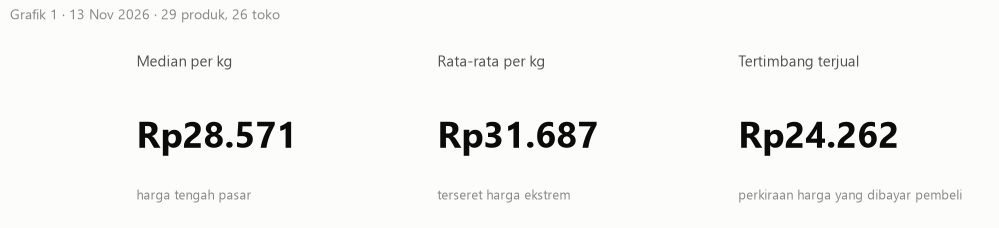

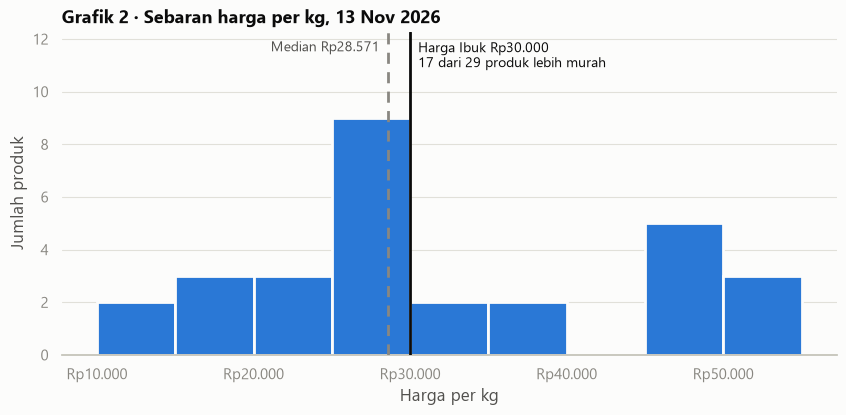

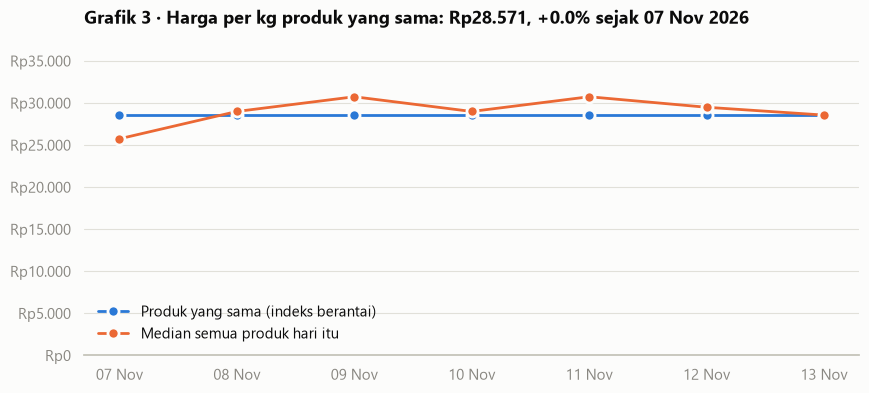

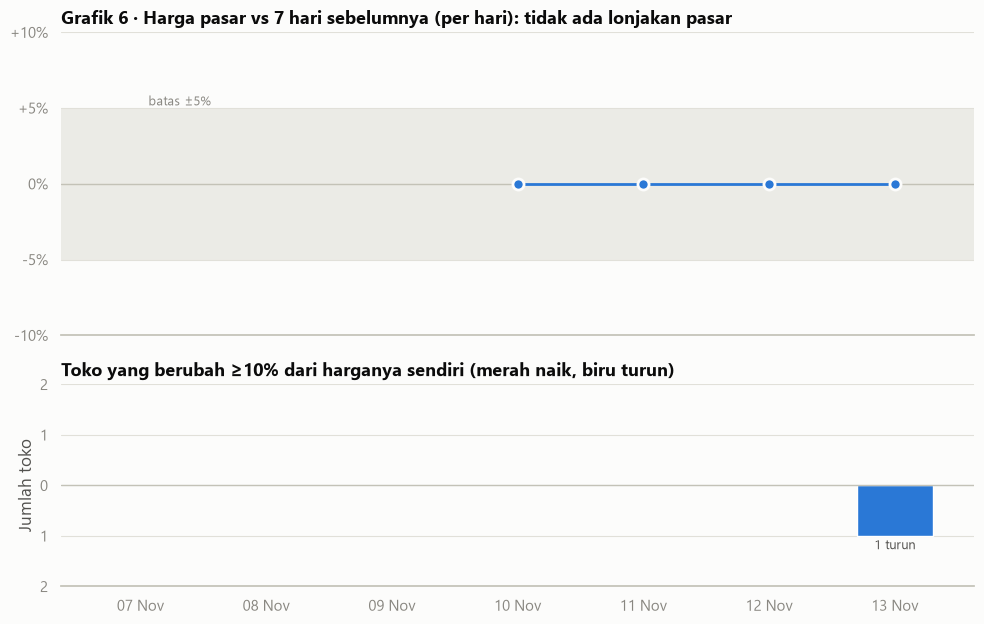

Lonjakan toko dalam rentang: 1


,tanggal,nama_toko,sumber,kota,sebelumnya,sekarang,perubahan
0,13 Nov 2026,rumindonesia,tokopedia,Jakarta Selatan,Rp32.500,Rp25.000,-23.1%


In [4]:
tampilkan("semua", *rentang_preset("semua", "Semua"))

### Filter

Pilih marketplace dan rentang. Tombol abu-abu = terkunci (arahkan kursor untuk alasannya).
*Kustom* memakai tanggal Dari–Sampai, dibatasi ke tanggal yang ada datanya.

In [5]:
pilih_pasar = w.ToggleButtons(options=[("Semua", "semua"), ("Tokopedia", "tokopedia"), ("Blibli", "blibli")],
                              value="semua")
tombol = {n: w.Button(description=n, layout=w.Layout(width="90px")) for n in [*DURASI, "Semua", "Kustom"]}
dari, sampai = w.DatePicker(description="Dari"), w.DatePicker(description="Sampai")
pesan, keluaran = w.HTML(), w.Output()
keadaan = {"rentang": "Semua"}


def gambar(*_):
    pasar = pilih_pasar.value
    status = status_preset(pasar)
    awal, akhir = batas_data(pasar)
    if keadaan["rentang"] in status and not status[keadaan["rentang"]][0]:
        keadaan["rentang"] = "Semua"                    # preset terkunci untuk marketplace ini
    for nama, b in tombol.items():
        terbuka, alasan = status.get(nama, (True, ""))
        b.disabled = not terbuka
        b.tooltip = alasan or nama
        b.button_style = "primary" if keadaan["rentang"] == nama else ""
    terkunci = [alasan for terbuka, alasan in status.values() if not terbuka]
    pesan.value = (f"<span style='color:{REDUP}'>Terkunci · " + " · ".join(terkunci) + "</span>") if terkunci else ""
    for p in (dari, sampai):
        p.min, p.max = awal.date(), akhir.date()
    if keadaan["rentang"] == "Kustom":
        mulai = max(pd.Timestamp(dari.value or awal), awal)
        akhir_ = min(pd.Timestamp(sampai.value or akhir), akhir)
    else:
        mulai, akhir_ = rentang_preset(pasar, keadaan["rentang"])
    with keluaran:
        keluaran.clear_output(wait=True)
        if mulai > akhir_:
            print("Rentang kosong: tanggal Dari sesudah Sampai.")
            return
        tampilkan(pasar, mulai, akhir_)


def pilih(nama):
    def klik(_):
        keadaan["rentang"] = nama
        gambar()
    return klik


for nama, b in tombol.items():
    b.on_click(pilih(nama))
pilih_pasar.observe(gambar, "value")
for p in (dari, sampai):
    p.observe(pilih("Kustom"), "value")

display(w.VBox([pilih_pasar, w.HBox(list(tombol.values())), w.HBox([dari, sampai]), pesan, keluaran]))
gambar()